# Q12: Time Series – University Electricity Consumption
**Aim:** To analyse monthly electricity consumption and forecast it using ARIMA.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
warnings.filterwarnings("ignore")

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("12_Time_Series_Electricity.csv")
except FileNotFoundError:
    np.random.seed(42)
    t = np.arange(50)
    df = pd.DataFrame({"Month": pd.date_range("2024-01-01", periods=50, freq="MS").strftime("%Y-%m"),
                       "Consumption_kWh": (50000 + 300 * t + 6000 * np.sin(2 * np.pi * t / 12)
                                           + np.random.normal(0, 1500, 50)).round()})
df.head()

,Month,Consumption_kWh
0,2024-01,50745.0
1,2024-02,53093.0
2,2024-03,56768.0
3,2024-04,59185.0
4,2024-05,56045.0


### 1. Convert Month to datetime index

In [3]:
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")
df.head()

,Consumption_kWh
Month,
2024-01-01,50745.0
2024-02-01,53093.0
2024-03-01,56768.0
2024-04-01,59185.0
2024-05-01,56045.0


### 2. Missing values, duplicate dates, ordering

In [4]:
print("Missing values:", df["Consumption_kWh"].isnull().sum())
print("Duplicate dates:", df.index.duplicated().sum())
print("In chronological order:", df.index.is_monotonic_increasing)
df = df[~df.index.duplicated()].sort_index().asfreq("MS")
df["Consumption_kWh"] = df["Consumption_kWh"].interpolate()
y = df["Consumption_kWh"]

Missing values: 0
Duplicate dates: 0
In chronological order: True


### 3. Descriptive statistics and line plot

count       50.00
mean     57071.78
std       5472.08
min      46500.00
25%      53310.50
50%      56594.00
75%      61148.25
max      68304.00
Name: Consumption_kWh, dtype: float64


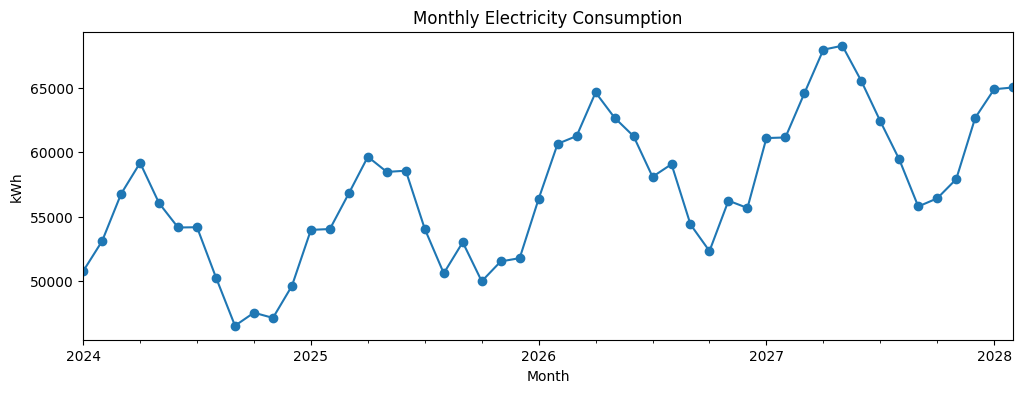

In [5]:
print(y.describe().round(2))
y.plot(figsize=(12, 4), marker="o", title="Monthly Electricity Consumption")
plt.ylabel("kWh")
plt.show()

### 4. 3, 6 and 12-month moving averages

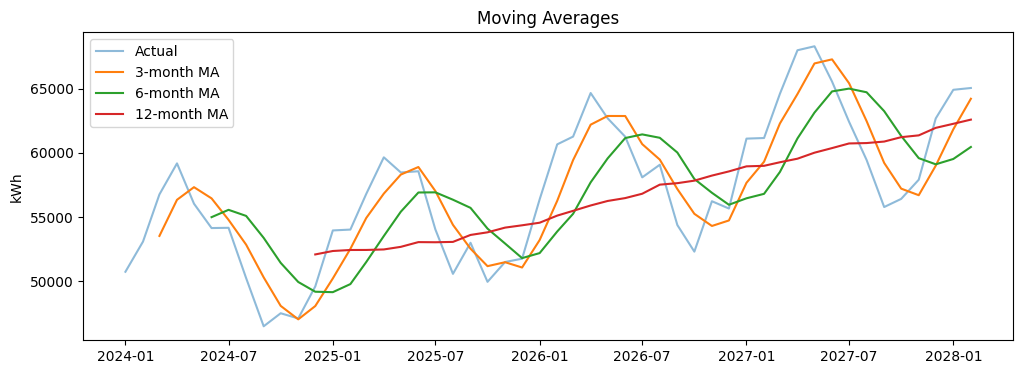

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(y, label="Actual", alpha=0.5)
for w in [3, 6, 12]:
    plt.plot(y.rolling(w).mean(), label=f"{w}-month MA")
plt.ylabel("kWh")
plt.title("Moving Averages")
plt.legend()
plt.show()

### 5. ADF test (H0: series is non-stationary)

In [7]:
adf = adfuller(y)
print(f"ADF = {adf[0]:.3f}, p = {adf[1]:.4f} ->", "Stationary" if adf[1] < 0.05 else "Non-stationary")
d = 0 if adf[1] < 0.05 else 1

ADF = 0.905, p = 0.9932 -> Non-stationary


### 6. First-order differencing and re-test

After differencing: ADF = -5.817, p = 0.0000 -> Stationary


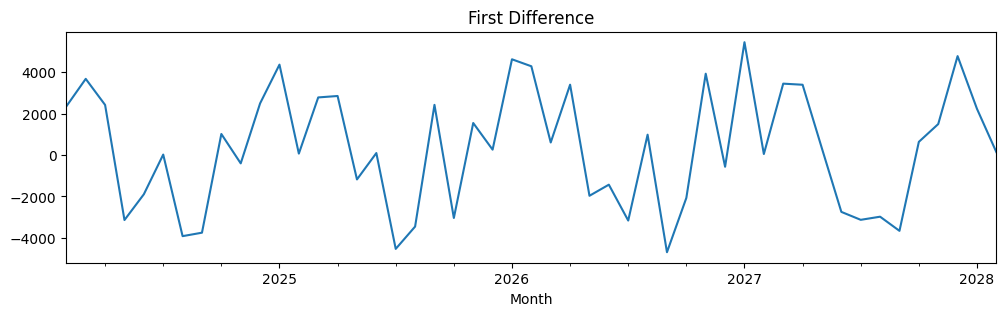

In [8]:
diff = y.diff().dropna()
adf2 = adfuller(diff)
print(f"After differencing: ADF = {adf2[0]:.3f}, p = {adf2[1]:.4f} ->", "Stationary" if adf2[1] < 0.05 else "Non-stationary")
diff.plot(figsize=(12, 3), title="First Difference")
plt.show()

### 7. ACF and PACF

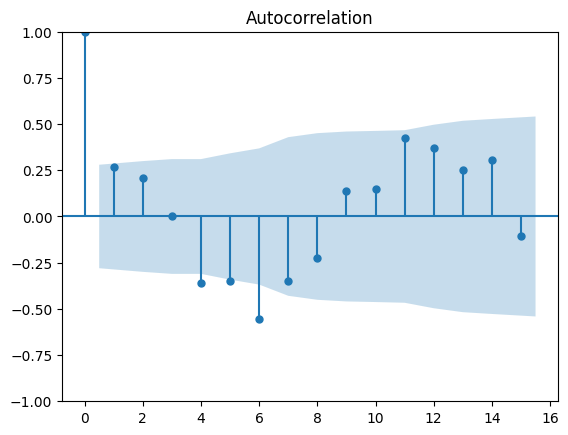

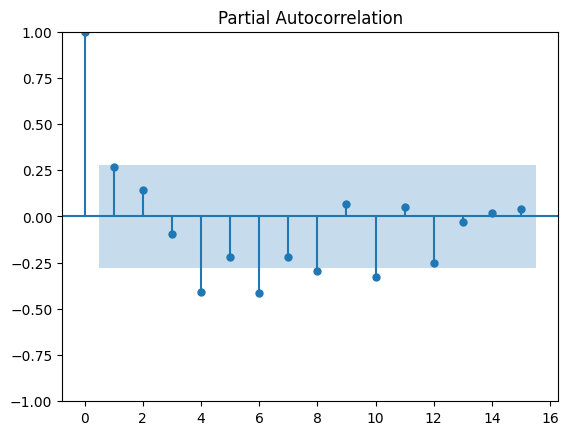

In [9]:
plot_acf(diff, lags=15)
plt.show()
plot_pacf(diff, lags=15)
plt.show()

Significant spikes at lag p in PACF suggest AR(p); at lag q in ACF suggest MA(q). ARIMA(1, d, 1) is used as a simple starting model.

### 8. ARIMA model and parameters

In [10]:
model = ARIMA(y, order=(1, d, 1)).fit()
print(model.summary())

                               SARIMAX Results                                
Dep. Variable:        Consumption_kWh   No. Observations:                   50
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -457.278
Date:                Wed, 04 Nov 2026   AIC                            920.556
Time:                        15:14:01   BIC                            926.231
Sample:                    01-01-2024   HQIC                           922.709
                         - 02-01-2028                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4402      0.541      0.814      0.416      -0.620       1.500
ma.L1         -0.3448      0.571     -0.604      0.546      -1.464       0.774
sigma2      7.329e+06   5.28e-08   1.39e+14      0.0

### 9. Chronological train-test split (last 10 months for testing)

In [11]:
train, test = y.iloc[:-10], y.iloc[-10:]
print("Train:", train.index[0].date(), "to", train.index[-1].date(), "| Test:", test.index[0].date(), "to", test.index[-1].date())

Train: 2024-01-01 to 2027-04-01 | Test: 2027-05-01 to 2028-02-01


### 10. Forecast next 3 months

2028-03-01    65200.11
2028-04-01    65263.98
2028-05-01    65292.09
Freq: MS, Name: predicted_mean, dtype: float64


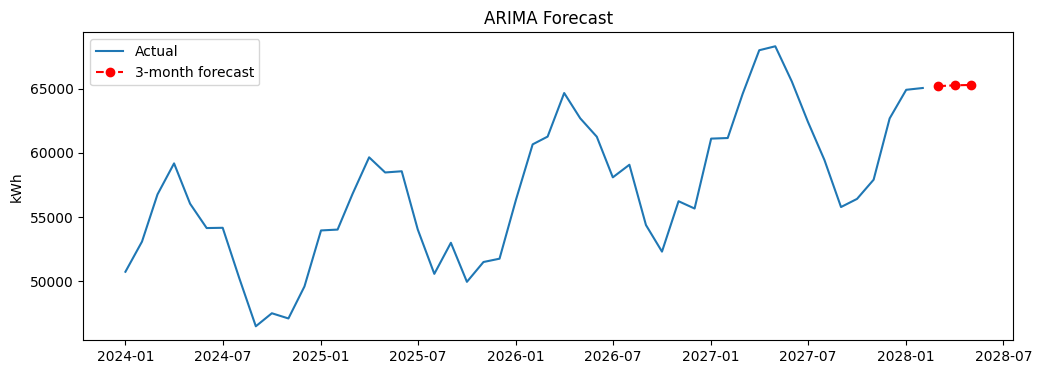

In [12]:
future = model.forecast(steps=3)
print(future.round(2))
plt.figure(figsize=(12, 4))
plt.plot(y, label="Actual")
plt.plot(future, "ro--", label="3-month forecast")
plt.ylabel("kWh")
plt.title("ARIMA Forecast")
plt.legend()
plt.show()

### 11. Test-set evaluation: MAE, RMSE, MAPE

In [13]:
pred = ARIMA(train, order=(1, d, 1)).fit().forecast(steps=len(test))
ma_pred = np.repeat(train.iloc[-3:].mean(), len(test))

def scores(actual, p):
    return {"MAE": mean_absolute_error(actual, p), "RMSE": np.sqrt(mean_squared_error(actual, p)),
            "MAPE_%": mean_absolute_percentage_error(actual, p) * 100}

print(pd.Series(scores(test, pred)).round(2))

MAE       6892.83
RMSE      8030.69
MAPE_%      11.63
dtype: float64


### 12. ARIMA vs moving-average baseline

          ARIMA  3-Month MA
MAE     6892.83     3832.37
RMSE    8030.69     4882.99
MAPE_%    11.63        6.51


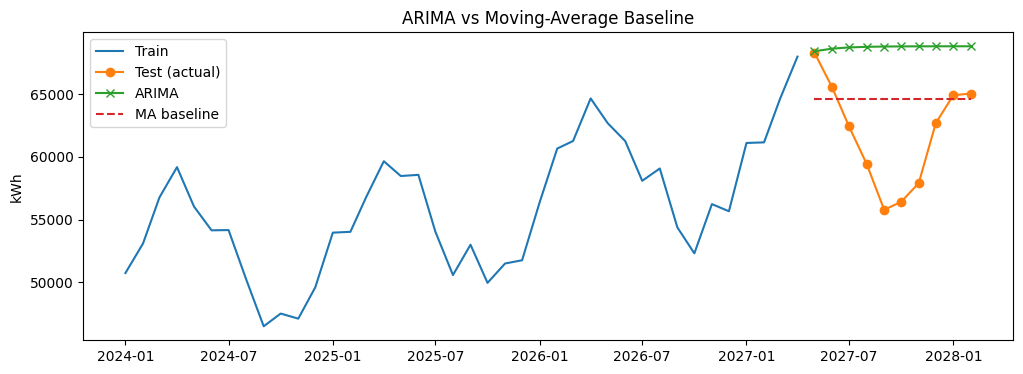

In [14]:
print(pd.DataFrame({"ARIMA": scores(test, pred), "3-Month MA": scores(test, ma_pred)}).round(2))
plt.figure(figsize=(12, 4))
plt.plot(train, label="Train")
plt.plot(test, label="Test (actual)", marker="o")
plt.plot(test.index, pred, label="ARIMA", marker="x")
plt.plot(test.index, ma_pred, label="MA baseline", linestyle="--")
plt.ylabel("kWh")
plt.title("ARIMA vs Moving-Average Baseline")
plt.legend()
plt.show()

The model with the lower MAE, RMSE and MAPE is the better forecaster.

**Result:** The electricity time series was explored, tested for stationarity, modelled with ARIMA, and forecasts were evaluated against a moving-average baseline.